# 01. 入門と基本データ構造（`CsrGraph`・`Layout2d`・相互運用・空間補助機能）

このノートブックでは、`egraph` v6 Python バインディングの基本的な考え方と中核データ構造を学びます。

> **重要: `egraph` v6 の設計方針**  
> `egraph` v6 は **グラフ構造の保持と高速なレイアウト計算・評価指標の計算に専念** しており、描画機能は内包していません。  
> ネットワーク図の可視化はすべて `matplotlib` / `networkx` / `numpy` などの Python ライブラリで行います。

### v5 からの移行について
従来の `Graph` / `DrawingEuclidean2d` / `TsNet` などをご利用だった方は、[`docs/MIGRATION_V6.md`](https://github.com/likr/egraph-rs/blob/master/docs/MIGRATION_V6.md)（リポジトリ内の `docs/MIGRATION_V6.md`）および [Sphinx API ドキュメント](https://egraph-py-docs.netlify.app/) をあわせてご参照ください。

In [ ]:
!pip install -q --pre "egraph[interop,viz]==6.0.0a8" matplotlib-fontja

## 1. 環境設定とプロット用ヘルパー関数の定義

`egraph` で計算した `Layout2d` 座標を `layout.coords(copy=False)` でゼロコピー取得し、`matplotlib.collections.LineCollection` + `ax.scatter` で高速に描画するヘルパーと、`egraph.interop.to_networkx` + `nx.draw_networkx` を使うヘルパーの 2 種類を用意します。

In [ ]:
\
import numpy as np
import scipy.sparse as sp
import networkx as nx
import igraph as ig
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle

# Apply Japanese font on Colab when matplotlib-fontja is installed
try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg
from egraph.interop import (
    from_igraph,
    from_networkx,
    from_scipy_csr,
    to_igraph,
    to_networkx,
    to_scipy_csr,
)

plt.rcParams["figure.dpi"] = 120
print(f"egraph version: {eg.__version__}")


def plot_graph_2d(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    ax=None,
    *,
    title: str = "",
    node_size: float = 18.0,
    edge_alpha: float = 0.25,
    edge_width: float = 0.6,
    node_color: str = "#1f77b4",
):
    '''Plot a CsrGraph and Layout2d strictly using matplotlib LineCollection + scatter.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(5.5, 4.5))

    # Access coordinates zero-copy as an (N, 2) NumPy array
    coords = layout.coords(copy=False)
    indptr = graph.indptr()
    indices = graph.indices()

    # Build unique edge segments for undirected graphs (or all arcs for directed graphs)
    segments = []
    n = graph.num_nodes
    directed = graph.is_directed
    for u in range(n):
        start, end = int(indptr[u]), int(indptr[u + 1])
        for v in indices[start:end]:
            v_int = int(v)
            if directed or u < v_int:
                segments.append([coords[u], coords[v_int]])

    if segments:
        lc = LineCollection(segments, colors="#666666", linewidths=edge_width, alpha=edge_alpha, zorder=1)
        ax.add_collection(lc)

    ax.scatter(coords[:, 0], coords[:, 1], s=node_size, c=node_color, edgecolors="white", linewidths=0.3, zorder=2)
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title)
    return ax


def plot_graph_nx(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    ax=None,
    *,
    title: str = "",
    node_size: int = 180,
):
    '''Convert to NetworkX with layout positions and draw via nx.draw_networkx.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(5.5, 4.5))
    nx_g = to_networkx(graph, layout=layout)
    pos = nx.get_node_attributes(nx_g, "pos")
    nx.draw_networkx(
        nx_g,
        pos=pos,
        ax=ax,
        node_size=node_size,
        node_color="#ff7f0e",
        edge_color="#888888",
        width=0.8,
        with_labels=True,
        font_size=7,
    )
    ax.set_aspect("equal")
    ax.set_axis_off()
    if title:
        ax.set_title(title)
    return ax

egraph version: 6.0.0a8


\
## 2. `CsrGraph` の構築と基本操作

`CsrGraph` は、頂点 ID (`uint32`) の Compressed Sparse Row (CSR) 形式でグラフの位相と数値重み（`weight_dtype="float64"` / `"float32"`）だけを保持する軽量構造です。
以下の 3 つのコンストラクタを提供します。

- `CsrGraph.from_edges(num_nodes, edges, weights=None, *, directed=False, sanitize=True, weight_dtype="float64")`
- `CsrGraph.from_edge_list(num_nodes, edges, weights=None, *, directed=False, sanitize=True, weight_dtype="float64")`
- `CsrGraph.from_csr(indptr, indices, weights=None, *, directed=False, sanitize=True, weight_dtype="float64")`

`sanitize=True`（デフォルト）では、無向グラフの対称化、自己ループの除去、重複辺の統合が自動的に行われます。さらに `len(g)`, `edges()`, `has_edge(u, v)`, `edge_weight(u, v)`, `is_connected()` などの基本ヘルパーを備えています。

In [ ]:
\
# 1) Construct undirected unweighted graph from edge array
edges_undirected = np.array([[0, 1], [1, 2], [2, 3], [3, 0], [0, 2], [2, 4]], dtype=np.uint32)
g_undir = eg.CsrGraph.from_edges(5, edges_undirected, directed=False)
print("from_edges (undirected):", g_undir)
print(
    f"  len={len(g_undir)}, num_nodes={g_undir.num_nodes}, num_edges={g_undir.num_edges}, "
    f"nnz={g_undir.nnz}, is_directed={g_undir.is_directed}, is_weighted={g_undir.is_weighted}, "
    f"is_connected={g_undir.is_connected()}"
)
print(f"  edges shape={g_undir.edges().shape}, has_edge(0,1)={g_undir.has_edge(0, 1)}, has_edge(0,4)={g_undir.has_edge(0, 4)}")

# 2) Construct directed weighted graph using from_edge_list with float32 weights
g_dir_w = eg.CsrGraph.from_edge_list(
    4,
    [(0, 1), (1, 2), (2, 3), (3, 0)],
    weights=[1.0, 2.5, 0.8, 1.2],
    directed=True,
    weight_dtype="float32",
)
print("from_edge_list (directed+weighted):", g_dir_w)
print(f"  weight_dtype={g_dir_w.weight_dtype}, edge_weight(0,1)={g_dir_w.edge_weight(0, 1)}, weights()={g_dir_w.weights()}")

# 3) Construct directly from raw CSR arrays
indptr = np.array([0, 2, 4, 6, 6], dtype=np.uint32)
indices = np.array([1, 2, 0, 2, 0, 1], dtype=np.uint32)
g_csr = eg.CsrGraph.from_csr(indptr, indices, directed=False)
print("from_csr:", g_csr, "indptr:", g_csr.indptr(), "indices:", g_csr.indices())

# 4) Node inspection and induced subgraph
print("degree(2) in g_undir:", g_undir.degree(2))
print("neighbors(2) in g_undir:", g_undir.neighbors(2))
sub_g = g_undir.induced_subgraph([0, 1, 2, 3])
print("induced_subgraph([0,1,2,3]):", sub_g, f"edges={sub_g.num_edges}")

from_edges (undirected): CsrGraph(num_nodes=5, num_edges=6, directed=False)
  len=5, num_nodes=5, num_edges=6, nnz=12, is_directed=False, is_weighted=False, is_connected=True
  edges shape=(6, 2), has_edge(0,1)=True, has_edge(0,4)=False
from_edge_list (directed+weighted): CsrGraph(num_nodes=4, num_edges=4, directed=True)
  weight_dtype=float32, edge_weight(0,1)=1.0, weights()=[1.  2.5 0.8 1.2]
from_csr: CsrGraph(num_nodes=4, num_edges=3, directed=False) indptr: [0 2 4 6 6] indices: [1 2 0 2 0 1]
degree(2) in g_undir: 4
neighbors(2) in g_undir: [0 1 3 4]
induced_subgraph([0,1,2,3]): CsrGraph(num_nodes=4, num_edges=5, directed=False) edges=5


\
## 3. 組み込みデータセット・合成グラフ生成と CSV パース (`parse_csr_csv`)

`egraph` v6 にはベンチマーク用データセットが組み込まれており、`list_datasets()` / `dataset_catalog()` / `dataset_info(name)` / `load_dataset(name)` で一覧・メタデータ・本体を取得できます。このうち **`poli` は非連結グラフ** であるため、連結成分の抽出 (`largest_connected_component()`) の挙動確認に最適です。

また、ベンチマークや多様体テスト用の合成グラフ生成器 7 種（`generate_sbm_graph`, `generate_weighted_graph`, `generate_layered_dag`, `generate_torus_grid`, `generate_spherical_icosphere`, `generate_spherical_grid`, `generate_hyperbolic_tree`）も組み込まれています。

`parse_csr_csv` は、1 行目に `num_nodes,num_edges`、続く行に 2 列整数 `u,v`（重みなし）または **3 列 `u,v,w`（重み付き）** を記述した CSV テキストを直接読み込めます。

In [ ]:
\
dataset_names = eg.list_datasets()
print(f"list_datasets() -> {len(dataset_names)} datasets: {dataset_names}")
info_karate = eg.dataset_info("karate")
print(f"dataset_info('karate'): nodes={info_karate.num_nodes}, edges={info_karate.num_edges}, source={info_karate.source!r}\n")

print(f"{'Dataset':<14} {'Nodes':>7} {'Edges':>8} {'NNZ':>8} {'LCC Nodes':>10} {'Min/Max Deg':>14}")
print("-" * 68)
for name in dataset_names:
    g = eg.load_dataset(name)
    lcc_g, _ = g.largest_connected_component()
    degs = [g.degree(u) for u in range(g.num_nodes)]
    print(
        f"{name:<14} {g.num_nodes:>7} {g.num_edges:>8} {g.nnz:>8} "
        f"{lcc_g.num_nodes:>10} {f'[{min(degs)}, {max(degs)}]':>14}"
    )

# Inspect largest_connected_component() on disconnected 'poli'
g_poli = eg.load_dataset("poli")
g_poli_lcc, orig_node_ids = g_poli.largest_connected_component()
print(f"\npoli LCC extraction: {g_poli.num_nodes} -> {g_poli_lcc.num_nodes} nodes, is_connected={g_poli_lcc.is_connected()}")
print("First 10 original node IDs in LCC:", orig_node_ids[:10])

# Built-in synthetic graph generator (SBM)
g_sbm_syn, sbm_blocks = eg.generate_sbm_graph([20, 20, 20], p_intra=0.35, p_inter=0.02, seed=42)
print(f"\ngenerate_sbm_graph([20,20,20]): nodes={g_sbm_syn.num_nodes}, edges={g_sbm_syn.num_edges}, blocks={np.unique(sbm_blocks).tolist()}")

# Demonstrate parse_csr_csv (both 2-column unweighted and 3-column weighted rows)
g_csv = eg.parse_csr_csv("4,4\n0,1\n1,2\n2,3\n3,0\n")
g_csv_w = eg.parse_csr_csv("3,2\n0,1,2.5\n1,2,0.75\n")
print(f"parse_csr_csv (2-col): nodes={g_csv.num_nodes}, edges={g_csv.num_edges}, weighted={g_csv.is_weighted}")
print(f"parse_csr_csv (3-col): nodes={g_csv_w.num_nodes}, edges={g_csv_w.num_edges}, weighted={g_csv_w.is_weighted}, w(0,1)={g_csv_w.edge_weight(0, 1)}")

list_datasets() -> 9 datasets: ['1138_bus', '3elt', 'USpowerGrid', 'dwt_1005', 'dwt_2680', 'karate', 'lesmis', 'poli', 'qh882']
dataset_info('karate'): nodes=34, edges=78, source='Zachary (1977)'

Dataset          Nodes    Edges      NNZ  LCC Nodes    Min/Max Deg
--------------------------------------------------------------------
1138_bus          1138     1458     2916       1138        [1, 17]
3elt              4720    13722    27444       4720         [3, 9]
USpowerGrid       4941     6594    13188       4941        [1, 19]
dwt_1005          1005     3808     7616       1005        [3, 26]
dwt_2680          2680    11173    22346       2680        [3, 18]
karate              34       78      156         34        [1, 17]
lesmis              77      254      508         77        [1, 36]
poli              3915     4119     8238       2343        [1, 63]
qh882              882     1533     3066        882        [1, 16]

poli LCC extraction: 3915 -> 2343 nodes, is_connected=True
Firs

\
## 4. `Layout2d` と `LayoutNd`（ゼロコピー座標バッファ）

`Layout2d` は 2 次元座標を内部では SoA（Structure of Arrays: `x` と `y` の連続配列）または指定 `dtype`（`"float64"` / `"float32"`）で管理し、Python 側へは `coords(copy=False)` によって **ゼロコピーの NumPy ビュー `(N, 2)`** を公開します。

- `coords(copy=False)` で得た配列を書き換えると、Rust 側の `Layout2d` も即座に更新されます。
- 独立したコピーが欲しい場合は `layout.copy()`（`Layout2d` / `LayoutNd` インスタンスを複製）または `copy_coords()` / `coords(copy=True)`（NumPy 配列を複製）を使用します。
- 3 次元以上の高次元埋め込みには `LayoutNd` を使用します（次元数は `.dims` プロパティ、要素アクセスは `get(i, d)` / `set(i, d, val)`、正規化は `normalize_std()`）。

In [ ]:
\
# Layout2d creation methods
l_zeros = eg.Layout2d.zeros(5, dtype="float64")
l_init = eg.Layout2d.init(5, seed=42, dtype="float64")
l_from = eg.Layout2d.from_coords(np.array([[0.0, 0.0], [1.0, 0.0], [1.0, 1.0], [0.0, 1.0]]))
l_f32 = eg.Layout2d.init(5, seed=42, dtype="float32")
l_cloned = l_init.copy()
print(f"dtypes: l_init={l_init.dtype}, l_f32={l_f32.dtype}, is_all_finite={l_init.is_all_finite()}, len={len(l_cloned)}")

# Zero-copy view mutation demo
view = l_init.coords(copy=False)
copied = l_init.copy_coords()
before_x0 = l_init.x(0)
view[0, 0] = 9.5
print(f"Mutated view[0,0]=9.5 -> l_init.x(0) changed from {before_x0:.4f} to {l_init.x(0):.4f}")
copied[1, 1] = -99.0
print(f"Mutated copy[1,1]=-99.0 -> l_init.y(1) stayed {l_init.y(1):.4f}")

# Element-wise setters and standard deviation normalization
l_init.set_x(0, 0.5)
l_init.set_y(0, -0.5)
l_init.normalize_std(target_std=1.0)
norm_coords = l_init.coords(copy=False)
print(f"After normalize_std(1.0): x_std={norm_coords[:, 0].std():.4f}, y_std={norm_coords[:, 1].std():.4f}")

# LayoutNd (3D buffer: .dims, .copy(), .get(), .set(), .normalize_std())
nd_zeros = eg.LayoutNd.zeros(4, 3, dtype="float64")
nd_custom = eg.LayoutNd.from_coords(np.arange(12, dtype=np.float64).reshape(4, 3))
nd_copy = nd_custom.copy()
nd_view = nd_custom.coords(copy=False)
nd_view[0, 2] = 42.0
nd_copy.set(0, 2, 7.5)
print(
    f"LayoutNd shape={nd_view.shape}, nd_zeros.dims={nd_zeros.dims}, "
    f"mutated [0,2]={nd_custom.get(0, 2)}, independent copy [0,2]={nd_copy.get(0, 2)}"
)
nd_copy.normalize_std(1.0)
print(f"LayoutNd normalize_std(1.0): axis std={np.round(nd_copy.coords(copy=False).std(axis=0), 4)}")

dtypes: l_init=float64, l_f32=float32, is_all_finite=True, len=5
Mutated view[0,0]=9.5 -> l_init.x(0) changed from -0.3083 to 9.5000
Mutated copy[1,1]=-99.0 -> l_init.y(1) stayed 0.2232
After normalize_std(1.0): x_std=1.1085, y_std=0.8782
LayoutNd shape=(4, 3), nd_zeros.dims=3, mutated [0,2]=42.0, independent copy [0,2]=7.5
LayoutNd normalize_std(1.0): axis std=[1.1171 1.1171 0.7102]


\
## 5. 外部ライブラリとの相互運用 (`egraph.interop`) と描画比較

`egraph.interop` を使うことで、既存の Python エコシステムとシームレスにデータをやり取りできます。

- `from_networkx` / `to_networkx`（`layout` に `Layout2d | LayoutNd | ManifoldLayout2d` を渡すと各ノードに `pos` 属性が付与されます）
- `from_scipy_csr` / `to_scipy_csr`
- `from_igraph` / `to_igraph`（`layout` に `Layout2d | LayoutNd | ManifoldLayout2d` を渡すと `vs["pos"]` が設定されます）

ここでは `karate`（小規模、NetworkX / igraph 相互変換と描画）と `dwt_1005`（中規模、`LineCollection` + `scatter` 描画）を実際にレイアウト・プロットしてみます。

from_networkx: nodes=34, edges=78, sample_ids=[0, 1, 2, 3, 4]
SciPy CSR shape=(34, 34), nnz=156 -> CsrGraph edges=78
from_igraph (Petersen): nodes=10, edges=15
to_igraph: vcount=34, has_pos=True | to_networkx(3D) pos len=3


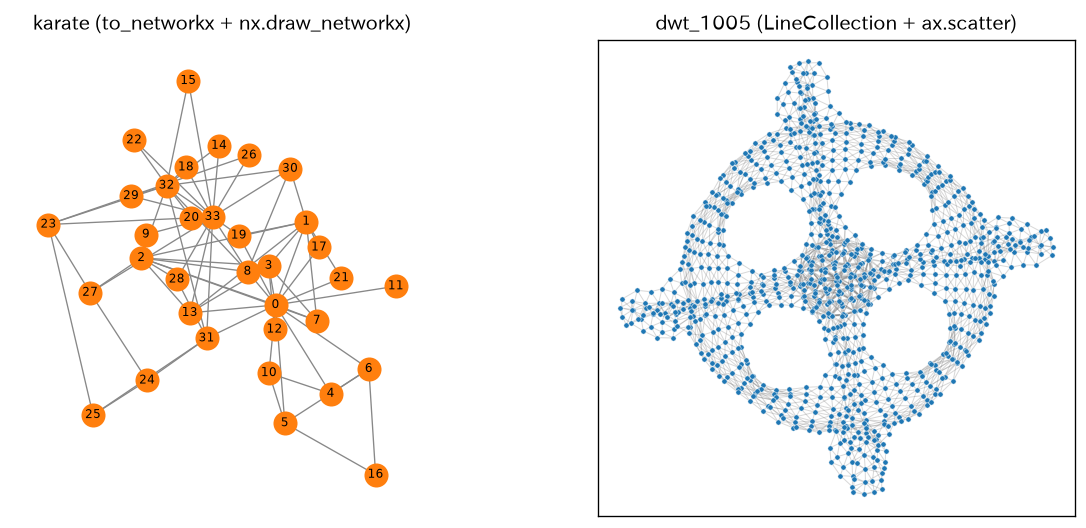

In [ ]:
\
# 1) NetworkX <-> CsrGraph roundtrip
nx_karate = nx.karate_club_graph()
g_karate_nx, node_ids = from_networkx(nx_karate)
print(f"from_networkx: nodes={g_karate_nx.num_nodes}, edges={g_karate_nx.num_edges}, sample_ids={node_ids[:5]}")

# 2) SciPy CSR <-> CsrGraph roundtrip
sp_mat = to_scipy_csr(g_karate_nx)
g_from_sp = from_scipy_csr(sp_mat)
print(f"SciPy CSR shape={sp_mat.shape}, nnz={sp_mat.nnz} -> CsrGraph edges={g_from_sp.num_edges}")

# 3) igraph <-> CsrGraph roundtrip (including 3D LayoutNd pos export)
ig_g = ig.Graph.Famous("Petersen")
g_petersen = from_igraph(ig_g)
print(f"from_igraph (Petersen): nodes={g_petersen.num_nodes}, edges={g_petersen.num_edges}")

# Compute layouts with egraph and render via NetworkX + matplotlib
layout_karate = eg.Layout2d.init(g_karate_nx.num_nodes, seed=42)
eg.StressMajorizationSolver.from_graph(g_karate_nx).run(layout_karate)

ig_karate = to_igraph(g_karate_nx, layout=layout_karate)
nd_karate_3d = eg.LayoutNd.init(g_karate_nx.num_nodes, 3, seed=42)
nx_karate_3d = to_networkx(g_karate_nx, layout=nd_karate_3d)
print(
    f"to_igraph: vcount={ig_karate.vcount()}, has_pos={'pos' in ig_karate.vs.attributes()} | "
    f"to_networkx(3D) pos len={len(nx_karate_3d.nodes[0]['pos'])}"
)

g_dwt = eg.load_dataset("dwt_1005")
layout_dwt = eg.pivot_mds_init(g_dwt, num_pivots=50, seed=42)
eg.SgdSolver.ortmann_sparse_stress(g_dwt, iterations=120, seed=42).run(layout_dwt)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_graph_nx(g_karate_nx, layout_karate, ax=axes[0], title="karate (to_networkx + nx.draw_networkx)")
plot_graph_2d(g_dwt, layout_dwt, ax=axes[1], title="dwt_1005 (LineCollection + ax.scatter)", node_size=10)
plt.tight_layout()
plt.show()

\
## 6. 空間幾何・空間木ユーティリティ（ドロネー三角形分割・矩形重なり・KD 木・3D 八分木）

`egraph` v6 は、2D 幾何および 3D/N-D 空間探索用の高速な補助機能を提供しています。

- `delaunay_triangulation(layout)` → `(edges, triangles)`
- `delaunay_to_csr(layout)` → ドロネーグラフを `CsrGraph` として返す
- `rectangle_overlaps(layout, half_widths, half_heights)` → 重なり合うノードペア `(i, j)` の配列を返す
- `DynamicKdTree(coords_or_layout)` → N-D 近傍探索（`k_nearest_excluding_self`, `within_radius` 等）
- `ArenaOctree3d()` → 3D Barnes-Hut 八分木（`build`, `compute_coulomb_repulsion`, `compute_maxent_repulsion` 等）

以下ではランダム配置上のドロネー三角形分割とノード矩形の重なり検出結果を可視化し、あわせて `DynamicKdTree` と `ArenaOctree3d` の動作を確認します。

Delaunay: edges=62, triangles=39, csr_edges=62
Detected overlapping pairs: 17
DynamicKdTree k_nearest_excluding_self(0, 3): indices=[9, 21, 22], dists=[0.303, 0.569, 0.878]
ArenaOctree3d: points=32, tree_nodes=121, repulsion_shape=(32, 3)


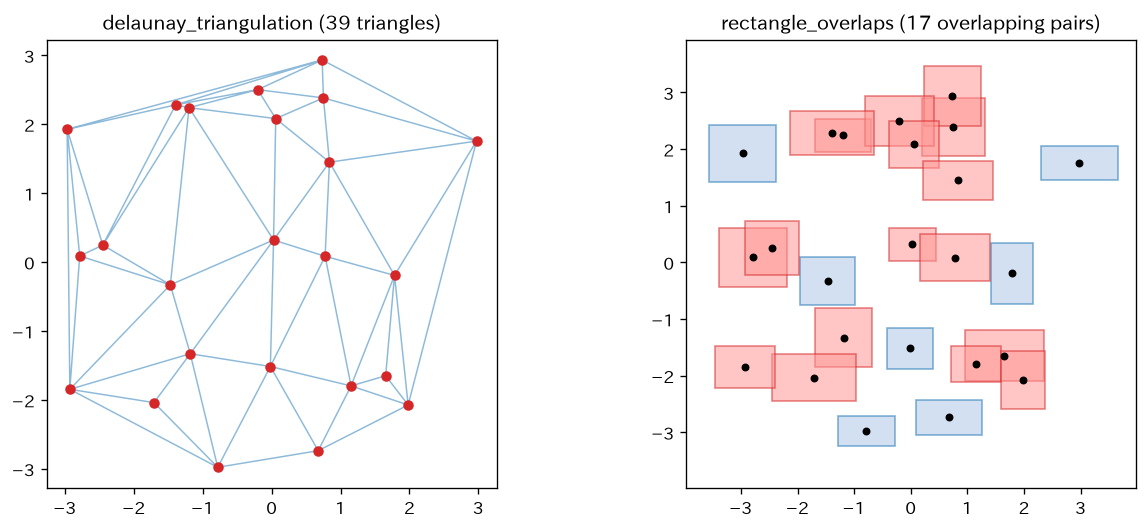

In [ ]:
\
rng = np.random.default_rng(7)
coords_pts = rng.uniform(-3.0, 3.0, size=(24, 2))
layout_pts = eg.Layout2d.from_coords(coords_pts)

# Delaunay triangulation and CsrGraph conversion
del_edges, del_tris = eg.delaunay_triangulation(layout_pts)
del_csr = eg.delaunay_to_csr(layout_pts)
print(f"Delaunay: edges={len(del_edges)}, triangles={len(del_tris)}, csr_edges={del_csr.num_edges}")

# Bounding box overlap detection
half_w = rng.uniform(0.35, 0.75, size=24)
half_h = rng.uniform(0.25, 0.55, size=24)
overlaps = eg.rectangle_overlaps(layout_pts, half_w, half_h)
overlap_nodes = set(overlaps.ravel().tolist()) if len(overlaps) > 0 else set()
print(f"Detected overlapping pairs: {len(overlaps)}")

# DynamicKdTree (2D/N-D coords or LayoutNd) & ArenaOctree3d (3D Barnes-Hut repulsion)
kd = eg.DynamicKdTree(layout_pts.coords(copy=False))
kd_idx, kd_dist = kd.k_nearest_excluding_self(0, 3)
print(f"DynamicKdTree k_nearest_excluding_self(0, 3): indices={kd_idx.tolist()}, dists={np.round(kd_dist, 3).tolist()}")

nd_3d_pts = eg.LayoutNd.init(32, 3, seed=42)
octree = eg.ArenaOctree3d()
octree.build(nd_3d_pts)
rep_3d = octree.compute_coulomb_repulsion(theta=0.5)
print(f"ArenaOctree3d: points={len(octree)}, tree_nodes={octree.node_count}, repulsion_shape={rep_3d.shape}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: Delaunay triangulation rendered via matplotlib triplot / LineCollection
ax0 = axes[0]
c = layout_pts.coords(copy=False)
ax0.triplot(c[:, 0], c[:, 1], del_tris, color="#1f77b4", alpha=0.5, linewidth=0.9)
ax0.scatter(c[:, 0], c[:, 1], c="#d62728", s=28, zorder=3)
ax0.set_aspect("equal")
ax0.set_title(f"delaunay_triangulation ({len(del_tris)} triangles)")

# Right: Rectangle overlaps highlighted in red
ax1 = axes[1]
for i in range(len(c)):
    is_ov = i in overlap_nodes
    rect = Rectangle(
        (c[i, 0] - half_w[i], c[i, 1] - half_h[i]),
        2.0 * half_w[i],
        2.0 * half_h[i],
        facecolor="#ff9896" if is_ov else "#aec7e8",
        edgecolor="#d62728" if is_ov else "#1f77b4",
        alpha=0.55,
        linewidth=1.0,
    )
    ax1.add_patch(rect)
ax1.scatter(c[:, 0], c[:, 1], c="black", s=14, zorder=3)
ax1.set_xlim(c[:, 0].min() - 1.0, c[:, 0].max() + 1.0)
ax1.set_ylim(c[:, 1].min() - 1.0, c[:, 1].max() + 1.0)
ax1.set_aspect("equal")
ax1.set_title(f"rectangle_overlaps ({len(overlaps)} overlapping pairs)")

plt.tight_layout()
plt.show()